# SymPhase tutorial 3 — elements in, everything out

```bash
symphase run Ti Ni Sn
```
or an input file `symphase.in` containing just

```
elements = Ti Ni Sn
```

What happens:
1. every known phase of Ti–Ni–Sn **and all sub-systems** is downloaded — Materials Project if `MP_API_KEY` is set, otherwise **OQMD (no key needed)**; cached in `data/`,
2. convex hull, E_hull, decompositions, stability margins (all cores),
3. all figures (hull, 3D surface, sub-system grids, E_hull bars, pseudo-binaries),
4. POSCARs of every phase within `ehull_window` (default 100 meV/atom),
5. optional VASP inputs + **Ibex job-array script** (`write_vasp=yes`),
6. `SUMMARY.html` / `SUMMARY.md` report.

All options: `symphase run -h` or the docstring of `symphase.auto`.

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

## 1. Live run (needs internet: OQMD or Materials Project)

On your laptop or the Ibex login node this downloads the real data. The cell falls back gracefully when offline.

In [2]:
from symphase.auto import run
try:
    h, info = run(["Ti", "Ni", "Sn"], outdir="live_Ti-Ni-Sn", ehull_window=0.05)
except ConnectionError as err:
    print("offline here ->", err)

SymPhase 1.0.0 — automatic analysis of Ti-Ni-Sn  (2 cores)  ->  live_Ti-Ni-Sn/
[1/6] collecting phases
  source: OQMD (no MP_API_KEY set)


offline here -> cannot reach http://oqmd.org/oqmdapi/formationenergy: <urlopen error [Errno -2] Name or service not known>


## 2. Offline demonstration with the toy data set

`source=csv` takes a CSV (here with structures for the key phases).

In [3]:
h, info = run(["Ti", "Ni", "Sn"], source="csv", csv=f"{EX}/hull/TiNiSn_ternary.csv",
              outdir="demo_Ti-Ni-Sn", write_vasp=True, tensors="charge,spin")

SymPhase 1.0.0 — automatic analysis of Ti-Ni-Sn  (2 cores)  ->  demo_Ti-Ni-Sn/
[1/6] collecting phases
  23 entries in Ti-Ni-Sn and its sub-systems
[2/6] convex hull

Convex hull: Ti-Ni-Sn  (3 elements, 23 entries, 15 stable)
  elemental references (eV/atom): Ti: -7.8900, Ni: -5.5700, Sn: -3.9800
  name                    formula         E (eV/at)    E_form    E_hull  stable decomposition / stability margin
                                                      (eV/at)  (meV/at)
  ------------------------------------------------------------------------------------------------------------------------------------
  TiNiSn-HH               TiNiSn            -6.4233   -0.6100       0.0  yes    stable, margin -97.4 meV/atom
  TiNi2Sn-FH              TiNi2Sn           -6.3375   -0.5850       0.0  yes    stable, margin -73.2 meV/atom
  TiNi3-D024              TiNi3             -6.6100   -0.4600       0.0  yes    stable, margin -270.0 meV/atom
  Ti5Sn3-D88              Ti5Sn3            -6.8537

  demo_Ti-Ni-Sn/figures/hull.png
  demo_Ti-Ni-Sn/figures/hull_surface.png


  demo_Ti-Ni-Sn/figures/subsystems_binary.png


  demo_Ti-Ni-Sn/figures/ehull_bar.png


  demo_Ti-Ni-Sn/figures/slice_TiNiSn_TiNi2Sn.png
  demo_Ti-Ni-Sn/figures/slice_TiNiSn_TiNi3.png


  demo_Ti-Ni-Sn/figures/slice_TiNi2Sn_TiNi3.png
[4/6] structures near the hull


  6 phases written to demo_Ti-Ni-Sn/structures/
[5/6] symmetry + response tensors (parallel)


  01_TiNiSn-HH                       F-43m (216)        F-43m1' (216.75)       AHE no   SHE 1/0  non-magnetic
  02_TiNi2Sn-FH                      Fm-3m (225)        Fm-3m1' (225.117)      AHE no   SHE 1/0  non-magnetic
  06_TiNi-B2                         Pm-3m (221)        Pm-3m1' (221.93)       AHE no   SHE 1/0  non-magnetic
  13_Ti-hcp                          P6_3/mmc (194)     P6_3/mmc1' (194.264)   AHE no   SHE 3/0  non-magnetic
  14_Ni-fcc                          Fm-3m (225)        Fm-3m1' (225.117)      AHE no   SHE 1/0  non-magnetic
  15_Sn-alpha                        Fd-3m (227)        Fd-3m1' (227.129)      AHE no   SHE 1/0  non-magnetic
[6/6] VASP inputs + Ibex job script
  6 run directories, submit with:  demo_Ti-Ni-Sn/vasp/submit_ibex.sh

Done in 2.7 s.  Open demo_Ti-Ni-Sn/SUMMARY.html


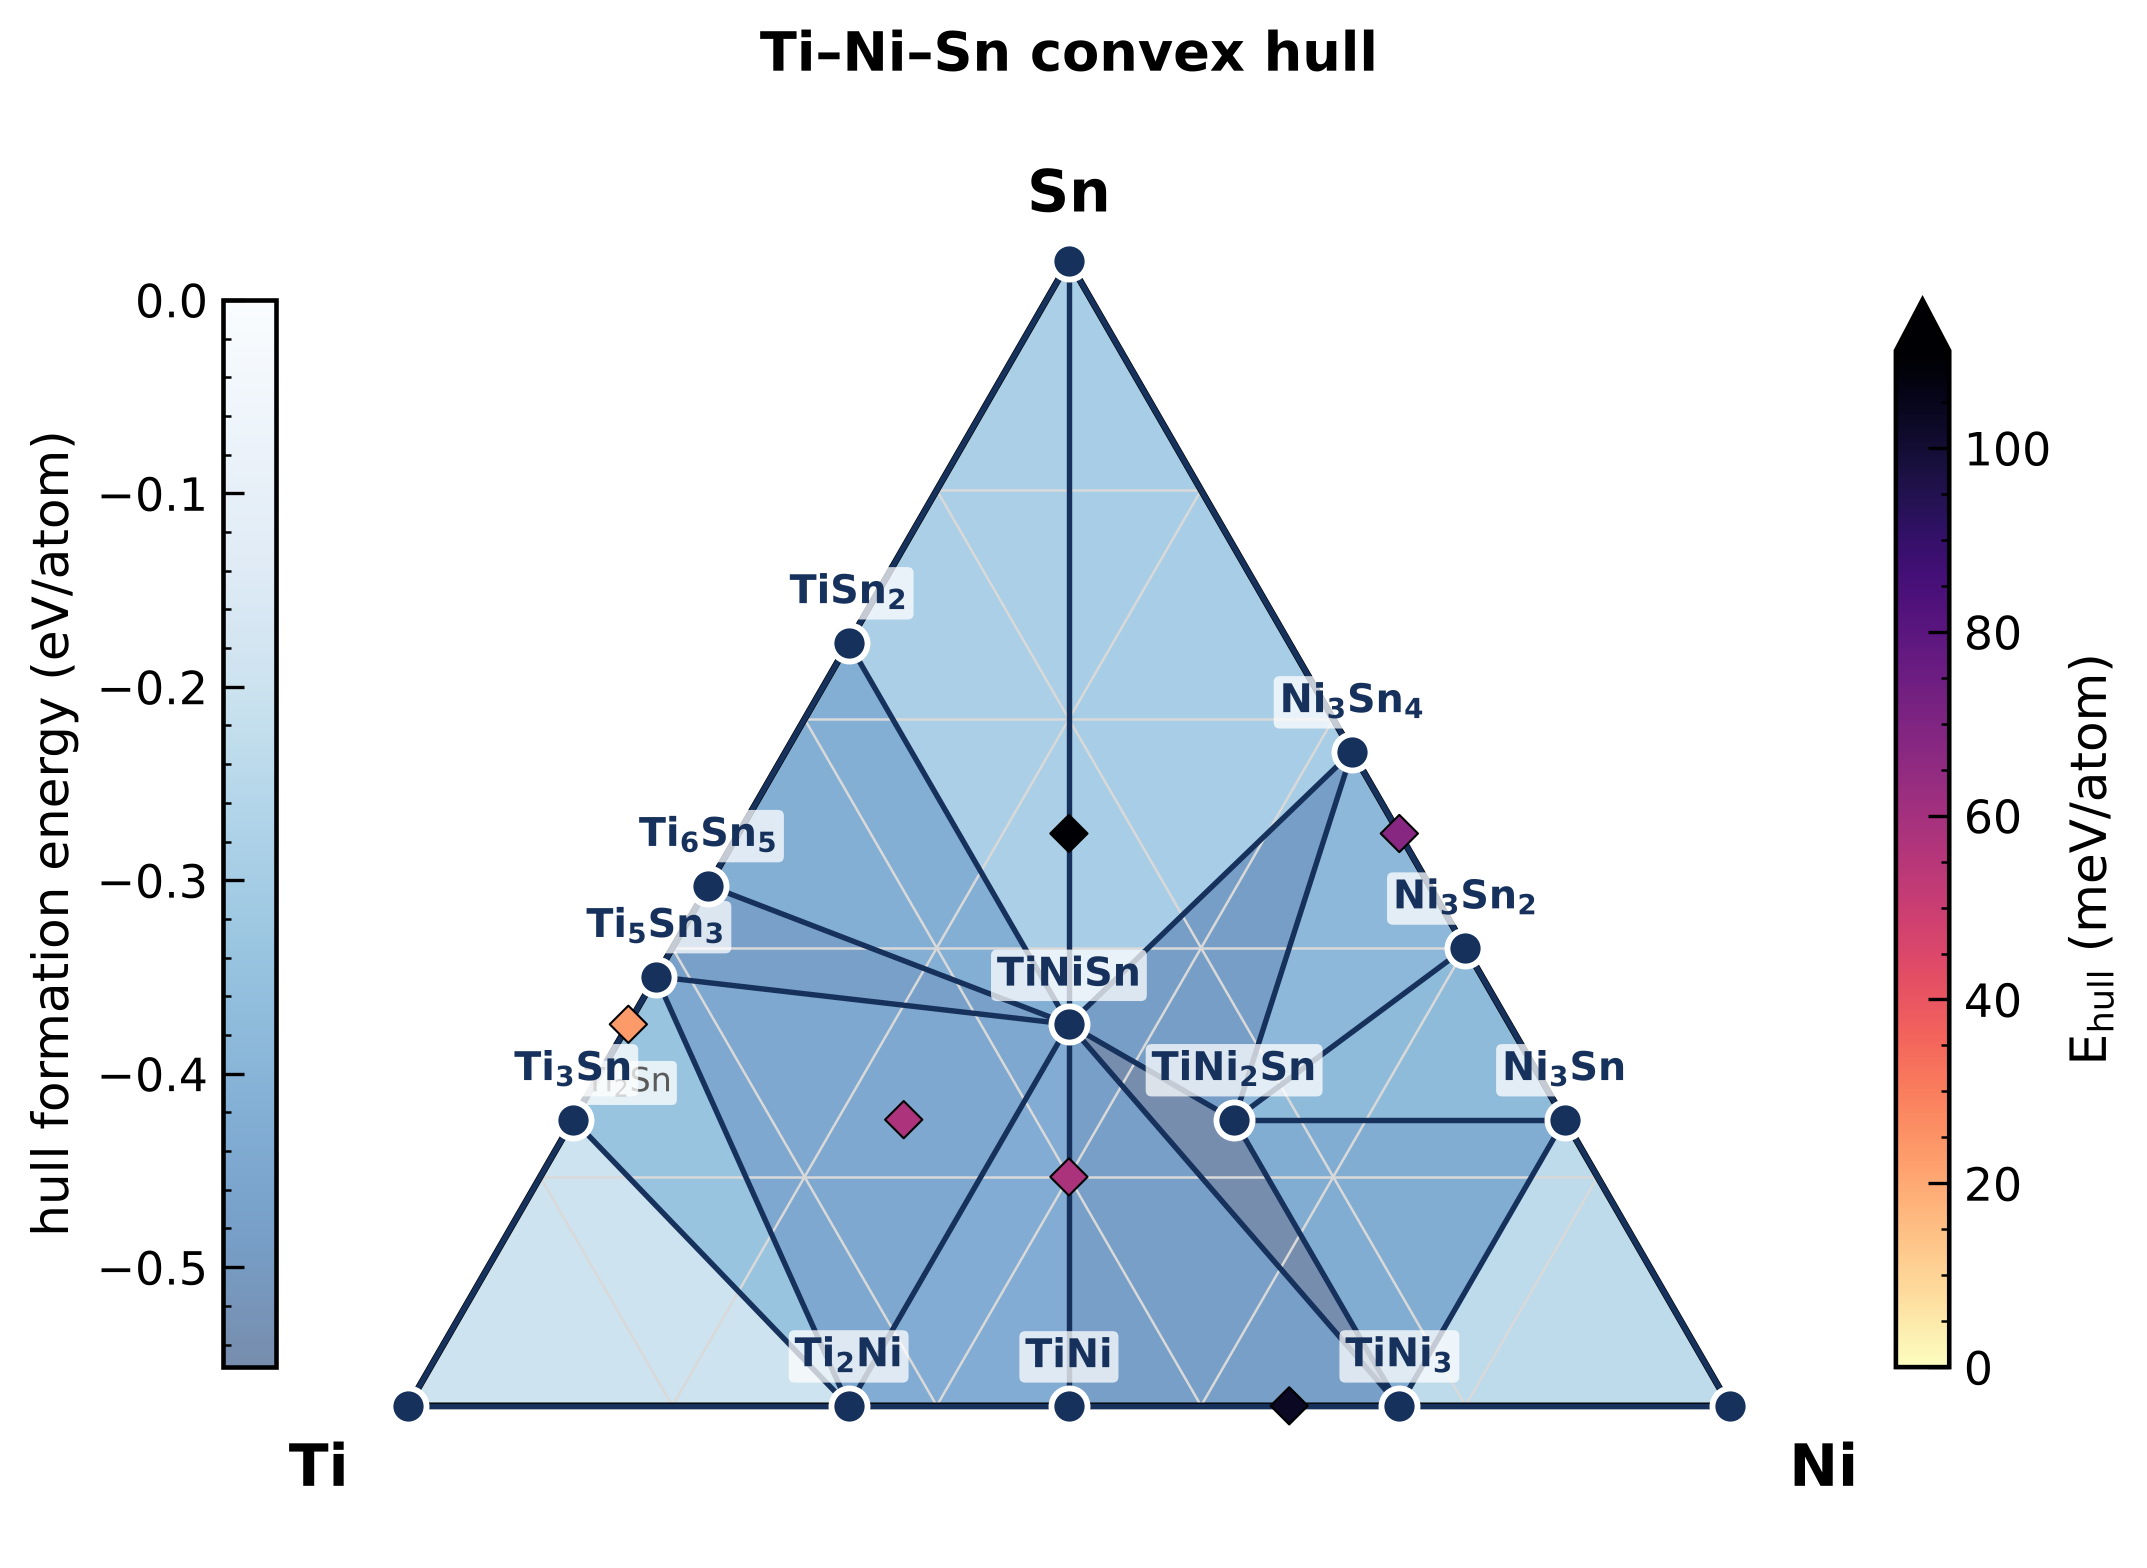

# SymPhase report — Ti-Ni-Sn

*SymPhase 1.0.0, source: csv, 23 entries, 15 stable phases, 2 cores, 2.6 s*

## Stable phases

| phase | E_form (eV/atom) | stability margin (meV/atom) |
|---|---:|---:|
| TiNiSn | -0.6100 | -97.4 |
| TiNi2Sn | -0.5850 | -73.2 |
| TiNi3 | -0.4600 | -270.0 |
| Ti5Sn3 | -0.4300 | -72.8 |
| Ti6Sn5 | -0.4000 | -19.1 |
| TiNi | -0.3800 | -16.0 |
| Ti2Ni | -0.3000 | -46.7 |
| Ni3Sn2 | -0.3000 | -46.0 |
| Ti3Sn | -0.2900 | -3.3 |
| Ni3Sn4 | -0.2700 | -55.7 |
| TiSn2 | -0.2500 | -5.6 |
| Ni3Sn | -0.2400 | -52.5 |
| Ti | 0.0000 |  |
| Ni | 0.0000 |  |
| Sn | 0.0000 |  |

## Phases within 100 meV/atom of the hull

| phase | id | E_form (eV/atom) | E_hull (meV/atom) | decomposition |
|---|---|---:|---:|---|
| Ti2Sn | Ti2Sn-B82 | -0.3600 | 23.3 | 0.667 Ti5Sn3 + 0.333 Ti3Sn |
| TiNiSn | TiNiSn-other | -0.5600 | 50.0 | 1.000 TiNiSn |
| Ti2NiSn | Ti2NiSn-inverseHeusler | -0.4200 | 57.8 | 0.469 TiNiSn + 0.281 Ti2Ni + 0.250 Ti5Sn3 |
| Ti2Ni2Sn | Ti2Ni2Sn-hyp | -0.4600 | 58.0 | 0.600 TiNiSn + 0.400 TiNi |
| Ti | Ti-bcc | 0.0600 | 60.0 | 1.000 Ti |
| NiSn | NiSn-hyp | -0.2150 | 67.5 | 0.583 Ni3Sn4 + 0.417 Ni3Sn2 |

## Symmetry and allowed responses (phases near the hull)

| phase | space group | magnetic space group (BNS) | MPG | P | PT | T | AHE | SHE T-even / T-odd | unconv. spin even / odd | spin group: class / NR splitting |
|---|---|---|---|:-:|:-:|:-:|:-:|:-:|:-:|---|
| 01_TiNiSn-HH | F-43m (216) | F-43m1' (216.75) | -43m1' | – | – | ✓ | – | 1 / 0 | 0 / 0 | non-magnetic / no non-relativistic spin splitting (spin-degenerate bands) |
| 02_TiNi2Sn-FH | Fm-3m (225) | Fm-3m1' (225.117) | m-3m1' | ✓ | ✓ | ✓ | – | 1 / 0 | 0 / 0 | non-magnetic / no non-relativistic spin splitting (spin-degenerate bands) |
| 06_TiNi-B2 | Pm-3m (221) | Pm-3m1' (221.93) | m-3m1' | ✓ | ✓ | ✓ | – | 1 / 0 | 0 / 0 | non-magnetic / no non-relativistic spin splitting (spin-degenerate bands) |
| 13_Ti-hcp | P6_3/mmc (194) | P6_3/mmc1' (194.264) | 6/mmm1' | ✓ | ✓ | ✓ | – | 3 / 0 | 0 / 0 | non-magnetic / no non-relativistic spin splitting (spin-degenerate bands) |
| 14_Ni-fcc | Fm-3m (225) | Fm-3m1' (225.117) | m-3m1' | ✓ | ✓ | ✓ | – | 1 / 0 | 0 / 0 | non-magnetic / no non-relativistic spin splitting (spin-degenerate bands) |
| 15_Sn-alpha | Fd-3m (227) | Fd-3m1' (227.129) | m-3m1' | ✓ | ✓ | ✓ | – | 1 / 0 | 0 / 0 | non-magnetic / no non-relativistic spin splitting (spin-degenerate bands) |

Full reports: `structures/<phase>/symmetry_report.txt`. Moments: from the database when available, otherwise non-magnetic.



In [4]:
from IPython.display import Image, Markdown, display
display(Image("demo_Ti-Ni-Sn/figures/hull.png", width=600))
display(Markdown(open("demo_Ti-Ni-Sn/SUMMARY.md").read().split("## Figures")[0]))

## 3. From database phases to your own DFT on Ibex

`write_vasp=yes` creates `vasp/<phase>/{POSCAR,INCAR,KPOINTS,POTCAR.spec}`, `joblist.txt` and `submit_ibex.sh`
(job array, `largemem`, 40 cores, oneAPI, your VASP binary and POTCAR library — all configurable in the input file):

In [5]:
print(open("demo_Ti-Ni-Sn/vasp/submit_ibex.sh").read()[:1400])

#!/bin/bash
# =============================================================================
#  SymPhase: VASP job array for all phases of Ti-Ni-Sn  (6 runs)
#  Usage (on the Ibex login node, inside this folder):   ./submit_ibex.sh
#  When all runs have finished:   cd ..; symphase run Ti Ni Sn source=vasp
# =============================================================================
set -e
ROOT=$(cd "$(dirname "$0")" && pwd)
cd "$ROOT"; mkdir -p logs
POTDIR=/home/shuklagn/potpaw_PBE

# --- build POTCARs on the login node (potpaw may not be visible on compute nodes)
while read -r D; do
  [ -f "$D/POTCAR" ] && continue
  : > "$D/POTCAR"
  for el in $(cat "$D/POTCAR.spec"); do
    [ -f "$POTDIR/$el/POTCAR" ] || { echo "missing $POTDIR/$el/POTCAR"; exit 1; }
    cat "$POTDIR/$el/POTCAR" >> "$D/POTCAR"
  done
  grep TITEL "$D/POTCAR" > "$D/potcar_titles.txt" || true
done < joblist.txt

cat > run_array.slurm <<'EOF'
#!/bin/bash
#SBATCH --partition=largemem
#SBATCH --nodes=1
#SBATCH --ntasks-

On Ibex:

```bash
cd demo_Ti-Ni-Sn/vasp && ./submit_ibex.sh      # builds POTCARs, submits the array
# ... when all jobs are done:
symphase run Ti Ni Sn source=vasp vasp_dir=demo_Ti-Ni-Sn/vasp outdir=TiNiSn_myDFT
```
The second run builds the hull purely from **your** energies (identical settings for every phase).

For the magnetic space group and conductivity tensors of any finished run: `cd vasp/01_TiNiSn...; symphase tensors`.

## 4. Running SymPhase itself as an Ibex job

`jobs/ibex_symphase.slurm` in the repository runs `symphase run` / `symphase hull` on a full node (all 40 cores),
`jobs/ibex_symphase_mpi.slurm` spreads very large screenings over several nodes with MPI.